<h3 style="color:yellow";> 1. Import the necessary packages </h3>

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

<h3 style="color:yellow";> 2. Load Dataset </h3>

Load the KNHANES 9th wave CSV and inspect shape, column names, and first rows.

In [2]:
df = pd.read_csv('../csv/KNHANES9.csv', low_memory=False) 
print(df.shape)
print(df.columns.tolist())
print(df.head())


(6997, 798)
['mod_d', 'ID', 'ID_fam', 'year', 'region', 'town_t', 'apt_t', 'psu', 'sex', 'age', 'age_month', 'incm', 'ho_incm', 'incm5', 'ho_incm5', 'edu', 'occp', 'wt_hs', 'wt_itvex', 'wt_ntr', 'wt_pft', 'wt_tot', 'wt_pfnt', 'kstrata', 'cfam', 'genertn', 'allownc', 'house', 'live_t', 'ainc_unit1', 'ainc_1', 'ainc', 'marri_1', 'marri_2', 'fam_rela', 'tins', 'npins', 'ID_F', 'ID_M', 'D_1_1', 'D_2_1', 'D_2_wk', 'DI1_dg', 'DI1_ag', 'DI1_pr', 'DI1_pt', 'DI1_2', 'DI2_dg', 'DI2_ag', 'DI2_pr', 'DI2_pt', 'DI2_2', 'DE1_dg', 'DE1_ag', 'DE1_pr', 'DE1_pt', 'DE1_3', 'DE1_31', 'DE1_32', 'DE1_33', 'DE1_34', 'DE1_35', 'DE1_4', 'DN1_dg', 'DN1_pt', 'DI3_dg', 'DI3_ag', 'DI3_2', 'DI4_dg', 'DI5_dg', 'DI5_ag', 'DI6_dg', 'DI6_ag', 'DJ2_dg', 'DJ2_ag', 'DC01_dg', 'DC01', 'DC01_tp1', 'DC01_ag', 'DJ4_dg', 'DJ4_ag', 'DJ4_3', 'DL1_dg', 'DL1_ag', 'DJ8_dg', 'DJ8_ag', 'DM4_dg', 'DM4_ag', 'DM4_pt', 'M_2_yr', 'M_2_rs', 'M_2_et', 'mt_nontrt', 'M_HL_1', 'M_HL_2', 'M_HL_3', 'M_HL_4', 'M_HL_5', 'M_HL_6', 'M_HL_7', 'M_HL_8'

<h3 style="color:yellow";> 2.1 Feature Selection & Age Filtering </h3>

Select the 10 candidate columns and restrict to respondents aged ≥ 40, where clinically significant tooth loss is most prevalent.

| Variable Name | Type/Format | Description | Value / Unit / Options |
| --- | --- | --- | --- |
| **O_TC** | N(2)* | 현존 자연치아 수 (자연치아 수의 총 합, 제3대구치 포함) | ☐☐ 개 |
| **HE_crea** | N(8.2) | 혈중크레아티닌 | ☐.☐☐ mg/dL |
| **HE_BMI** | N(8.1)* | 체질량지수 | ☐☐☐.☐ kg/m² |
| **HE_HbA1c** | N(8.1) | 당화혈색소 | ☐☐.☐ % |
| **BM7** | N(1) | 씹기 문제| 1.매우 불편함<br>2. 불편함<br>3.그저 그러함<br> 4. 불편하지 않음 <br>5. 전혀 불편하지 않음 <br>8. 비행당 <br>9.모름, 무응답 |
| **BD1** | N(1) | 평생음주경험 | 1. 술을 마셔 본 적 없음<br>2. 있음<br>8. 비해당(소아)<br>9. 모름, 무응답 |
| **edu** | N(1) | 교육수준 재분류 코드 (졸업은 현 학력으로, 수료·중퇴·재학·휴학은 이전 학력으로 분류) | 1. 초졸 이하<br>2. 중졸<br>3. 고졸<br>4. 대졸 이상 |
| **ho_incm** | N(1) | 소득 4분위수(가구) | 1. 하<br>2. 중하<br>3. 중상<br>4. 상 |
| **sex** | N(1) | 성별 | 1. 남자<br>2. 여자 |
| **age** | N(3) | 나이 | ☐☐☐ 세<br>1~79. 1~79세<br>80. 80세 이상 |


In [46]:
raw_columns = ['age', 'sex', 'ho_incm', 'edu', 'BD1', 'BM7', 'HE_HbA1c', 'HE_BMI', 'HE_crea', 'O_TC']

age_threshold = 40 
df_subset = df[raw_columns].copy()
df_subset = df_subset[df_subset['age'] >= age_threshold]
#^ creating an age threshold for filtering; according to the research papers age of 40~50 is primarily used 
# therefore having a 40 age threshold would seem fit. This is created to change the age whenever it's possible
print(df_subset.shape)
print(df_subset.columns.tolist())

(4680, 10)
['age', 'sex', 'ho_incm', 'edu', 'BD1', 'BM7', 'HE_HbA1c', 'HE_BMI', 'HE_crea', 'O_TC']


<h3 style="color:yellow";> 2.2 EDA - Age Distribution </h3>

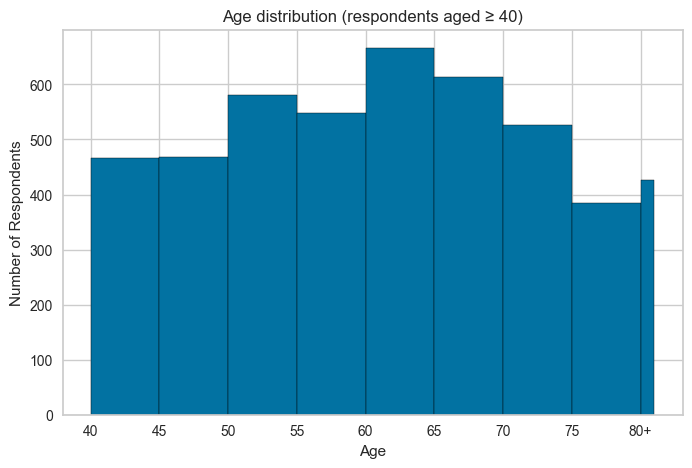

In [47]:
plt.figure(figsize=(8,5))
bins = list(range(40,81,5)) + [81]
plt.hist(df_subset['age'], bins=bins, edgecolor='black')
plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.title("Age distribution (respondents aged ≥ 40)")
ticks = list(range(40,81,5))
labels = [str(t) for t in ticks[:-1] + ['80+']]
plt.xticks(ticks, labels)
plt.show()

<h2 style="color:#FFA500";> 3. Target Variable — Cleaning & Binary Label </h2>

Clean `O_TC` (total tooth count) and produce a binary classification target:

- **a.** The sentinel value `-1.80E+308` represents a missing/invalid entry in the raw KNHANES encoding.
- **b.** `pd.to_numeric(..., errors='coerce')` converts it and any other non-numeric values to `NaN`.
- **c.** Rows where `O_TC` is `NaN` are dropped; only records with a valid tooth count are kept.
- **d.** Binary label `O_TC_`: `1` if tooth count < 20 (functionally impaired), `0` otherwise.
- **e.** Class imbalance is assessed via the ratio of majority (0) to minority (1) class counts.


In [48]:
print(df_subset[pd.to_numeric(df_subset['O_TC'], errors='coerce').isna()]['O_TC'].unique())
# ^ finds all non numeric codes in the O_TC column and displays what those 'errors' were, in this case it 
# was ['-1.80E+308']

df_subset['O_TC'] = pd.to_numeric(df_subset['O_TC'], errors='coerce')
# if a value can't be converted replace it to NaN instead of raising an error 

df_subset['O_TC'] = df_subset['O_TC'].replace(-1.80e308, np.nan)   
# ^ in the dataset of KNHANES O_TC column there are values such as "-1.80e308" <-- this is a numeric 
# value therefore it needs to be specified before filtering 

before_drop = len(df_subset)
df_subset = df_subset.dropna(subset=['O_TC'])
print(f"Rows droppped (NaN O_TC): {before_drop - len(df_subset)}")
# ^ to know how many rows were dropped because of NaN; not required to the code --  just to visualize

df_subset['O_TC_'] = (df_subset['O_TC'] < 20).astype(int)
# ^ a lot of research papers determined O_TC value below 20 is considered impactful to the normal
# chewing and digestion problems. 
# "astype(int) --> converts True = 1 and False = 0"

label_counts    = df_subset['O_TC_'].value_counts()
# ^ counts how many values are there in the new 'O_TC_' column of 0s and 1s 
label_0         = label_counts[0]
label_1         = label_counts[1]
imbalance_ratio = label_0 / label_1

print(f"Age filter: >= {age_threshold}")
print(f"Label 0 (≥20 teeth): {label_0}")
print(f"Label 1 (<20 teeth): {label_1}")
print(df_subset['O_TC'].value_counts(dropna=False).head(20))
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

print(f"NaN count: {df_subset['O_TC'].isna().sum()}")

['-1.80E+308']
Rows droppped (NaN O_TC): 533
Age filter: >= 40
Label 0 (≥20 teeth): 3242
Label 1 (<20 teeth): 905
O_TC
28.0    911
27.0    451
26.0    353
24.0    220
25.0    208
29.0    196
32.0    183
23.0    182
0.0     179
30.0    135
22.0    119
21.0    115
20.0     93
31.0     76
19.0     71
16.0     59
17.0     54
18.0     53
15.0     41
12.0     39
Name: count, dtype: int64
Imbalance ratio: 3.58
NaN count: 0


<h3 style="color:yellow";> 3.1 O_TC Count </h3>

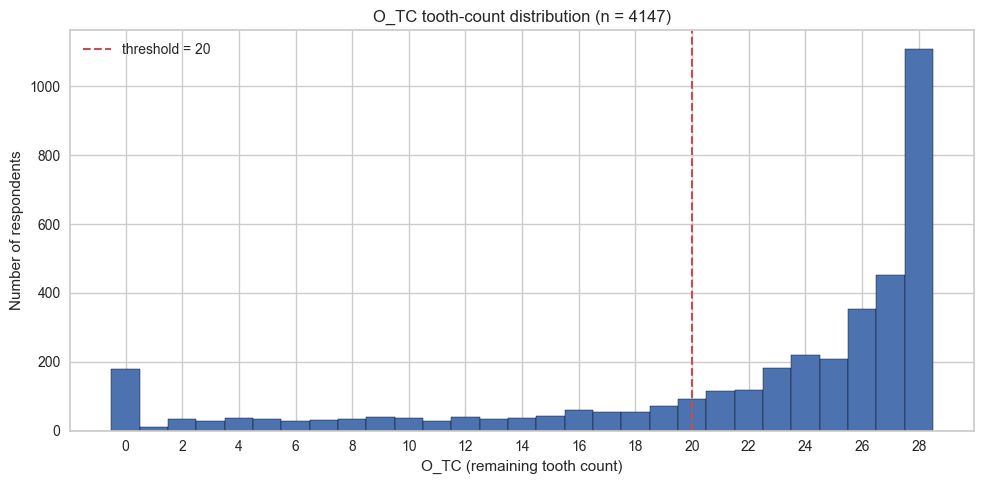

In [49]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_subset['O_TC'], bins=range(0, 30), color='#4C72B0',
        edgecolor='black', align='left')
ax.set_xlabel('O_TC (remaining tooth count)')
ax.set_ylabel('Number of respondents')
ax.set_title(f'O_TC tooth-count distribution (n = {len(df_subset)})')
ax.set_xticks(range(0, 29, 2))


ax.axvline(20, color='#C44E52', linestyle='--', linewidth=1.5,
           label=f'threshold = 20')
ax.legend()

plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 3.2 Class imbalance </h3>

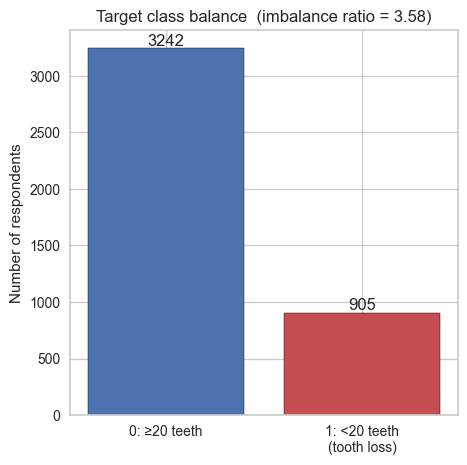

In [50]:
counts = df_subset['O_TC_'].value_counts().sort_index()

plt.figure(figsize=(5, 5))
bars = plt.bar(
    ['0: ≥20 teeth', '1: <20 teeth\n(tooth loss)'],
    counts.values,
    color=['#4C72B0', '#C44E52'],
    edgecolor='black'
)
plt.ylabel('Number of respondents')
plt.title(f'Target class balance  (imbalance ratio = {counts[0] / counts[1]:.2f})')

# annotate each bar with its count
for bar, n in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, n, str(n), ha='center', va='bottom')

plt.show()

<h2 style="color:#FFA500";> 4. Missing Value Audit & Invalid-Code Replacement </h2>

Survey responses use reserved codes (8, 9, 88, 99, 888, 999) for refusals and non-applicable items — these are **not** true values and must be replaced with `NaN` before modelling.

- **Survey columns** (`BD1`, `edu`, `ho_incm`, `BM7`): replace invalid codes with `NaN`.
- **Lab columns** (`HE_HbA1c`, `HE_BMI`, `HE_crea`): coerce to numeric and nullify sentinel magnitudes (≥ 1e10).
- Creatinine values ≤ 0 are physiologically impossible and are also nullified.


In [51]:

invalid_codes = [8, 9, 88, 99, 888, 999]
survey_cols   = ['BD1', 'edu', 'ho_incm', 'BM7']
lab_cols      = ['HE_HbA1c', 'HE_BMI', 'HE_crea']
# ^survey-reported vs clinically measured. The distinction matters for 
# - preprocessing (e.g. lab values get standard scaling, survey values may need encoding).

df_subset[survey_cols] = df_subset[survey_cols].replace(invalid_codes, np.nan)
df_subset[lab_cols]    = df_subset[lab_cols].apply(pd.to_numeric, errors='coerce')
df_subset[lab_cols]    = df_subset[lab_cols].where(df_subset[lab_cols].abs() < 1e10, np.nan)
# ^ So any lab value ≥ 1,000,000,000 (likely a sentinel/placeholder like 9999999999) 
# gets nulled out.


# Creatinine must be positive
df_subset.loc[df_subset['HE_crea'] <= 0, 'HE_crea'] = np.nan

print("NaN counts per column after cleaning:")
total = len(df_subset)
for col in survey_cols:
    count = df_subset[col].isna().sum()
    pct = (count/total) * 100 
    print(f"{col}: {count} | ({pct:.1f}%)")
for col in lab_cols:
    count = df_subset[col].isna().sum()
    pct = (count/total) * 100 
    print(f"{col}: {count} | ({pct:.1f}%)")


NaN counts per column after cleaning:
BD1: 0 | (0.0%)
edu: 0 | (0.0%)
ho_incm: 0 | (0.0%)
BM7: 0 | (0.0%)
HE_HbA1c: 123 | (3.0%)
HE_BMI: 79 | (1.9%)
HE_crea: 123 | (3.0%)


<h3 style="color:yellow";> 4.1 NaN Count </h3>

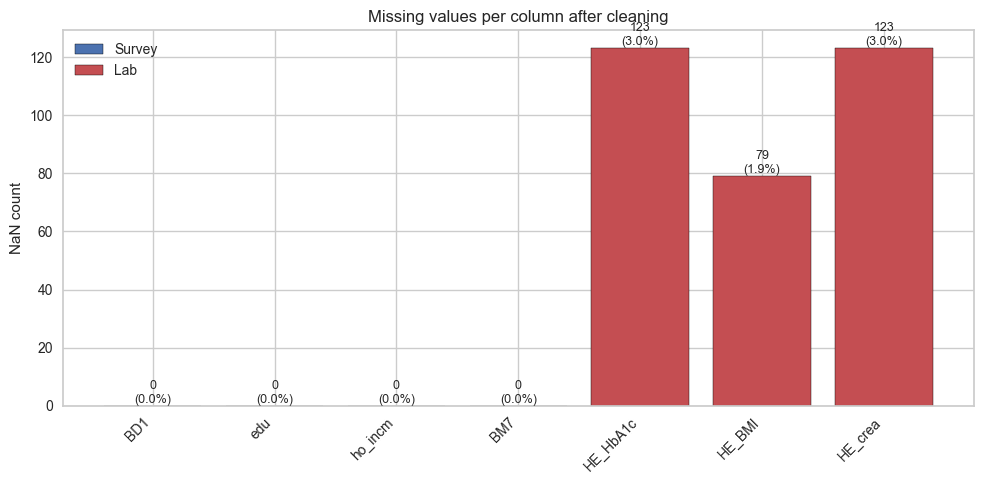

In [ ]:
audit_cols = ['BD1', 'edu', 'ho_incm', 'BM7',
              'HE_HbA1c', 'HE_BMI', 'HE_crea']

na_count = df_subset[audit_cols].isna().sum()
na_pct   = na_count / len(df_subset) * 100

# colour survey vs lab columns differently
lab_cols = ['HE_HbA1c', 'HE_BMI', 'HE_crea']
colors = ['#C44E52' if c in lab_cols else '#4C72B0' for c in audit_cols]

plt.figure(figsize=(10, 5))
bars = plt.bar(audit_cols, na_count.values, color=colors, edgecolor='black')

plt.ylabel('NaN count')
plt.title('Missing values per column after cleaning')
plt.xticks(rotation=45, ha='right')

# annotate each bar with count and percentage
for bar, n, p in zip(bars, na_count.values, na_pct.values):
    plt.text(bar.get_x() + bar.get_width() / 2, n,
             f'{n}\n({p:.1f}%)', ha='center', va='bottom', fontsize=9)

# legend for the two column types
from matplotlib.patches import Patch
plt.legend(handles=[Patch(facecolor='#4C72B0', edgecolor='black', label='Survey'),
                    Patch(facecolor='#C44E52', edgecolor='black', label='Lab')])

plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 4.2 Ordinal Remapping </h3>

Recode ordinal survey variables so that **higher values consistently indicate a worse health-related behaviour**, aligning all features for intuitive model interpretation.

| Column | Original coding | After remapping |
|--------|-----------------|-----------------|
| `BM7` | 1 = very active → 5 = sedentary | Reversed: `6 − BM7` (higher = more active → lower after reversal = healthier) |


In [10]:
df_subset[survey_cols] = df_subset[survey_cols].apply(pd.to_numeric, errors='coerce')
df_subset[survey_cols] = df_subset[survey_cols].replace(invalid_codes, np.nan)

df_subset['BM7']  = 6 - df_subset['BM7']

<h3 style="color:yellow";> 4.3 Derived Feature — eGFR (CKD-EPI 2021) </h3>

Replace raw serum creatinine with estimated Glomerular Filtration Rate (eGFR) using the **CKD-EPI 2021 creatinine equation**. eGFR is a more clinically interpretable measure of kidney function than creatinine alone and reduces the sex-dependence of the raw value.

`sex` and `HE_crea` are dropped after the derivation.

2021 CKD-EPI Creatinine Equation
The 2021 CKD-EPI eGFRcr equation estimates GFR using age, sex, and serum creatinine.2

The equation can be expressed as a single equation:

<h4 style="color:#7FDBFF";> eGFR = 142 × min(SCr/κ, 1)^α × max(SCr/κ, 1)^(-1.200) × 0.9938^Age × 1.012 (if female) </h4>

Abbreviations/units

-   eGFR = estimated GFR in mL/min/1.73 m2
-   SCr = standardized serum creatinine in mg/dL
-   κ = 0.7 (females) or 0.9 (males)
-   α = -0.241 (females) or -0.302 (males)
-   min = indicates the minimum of SCr/κ or 1
-   max = indicates the maximum of SCr/κ or 1
-   age = years

source:https://www.niddk.nih.gov/research-funding/research-programs/kidney-clinical-research-epidemiology/laboratory/glomerular-filtration-rate-equations/adults

In [53]:
def calculate_egfr(row):
    scr = row['HE_crea']
    age = row['age']
    sex = row['sex']   # KNHANES: 1 = male, 2 = female

    if pd.isna(scr) or pd.isna(sex):
        return np.nan

    if sex == 2:   # female
        kappa, alpha, sex_factor = 0.7, -0.241, 1.012
    else:          # male
        kappa, alpha, sex_factor = 0.9, -0.302, 1.0

    ratio = scr / kappa
    return (142
            * (min(ratio, 1) ** alpha)
            * (max(ratio, 1) ** -1.200)
            * (0.9938 ** age)
            * sex_factor)

df_subset['eGFR'] = df_subset.apply(calculate_egfr, axis=1)
df_subset = df_subset.drop(columns=['HE_crea', 'sex'])

<h3 style="color:yellow";> 4.4 EDA — Clinical Feature Distributions </h3>
Inspect the raw distributions of the key clinical exposures (HbA1c, eGFR, BMI)
before imputation and scaling. The dashed line marks the HbA1c ≥ 6.5% diabetes cutoff.

there is no cutoff for eGFR because the average value of eGFR is signficantly based on a person's age, sex, and other factors

|                          | HbA1c                             | BMI                                 |
| ------------------------ | --------------------------------- | ----------------------------------- |
| Measures                 | Blood-sugar control               | Body fatness                        |
| Role                     | **Diagnostic** (defines diabetes) | **Risk factor** (predicts diabetes) |
| Cutoff for diabetes      | Yes — ≥ 6.5%                      | No                                  |
| Relationship to diabetes | _Is_ the disease state            | A _cause/correlate_ of it           |

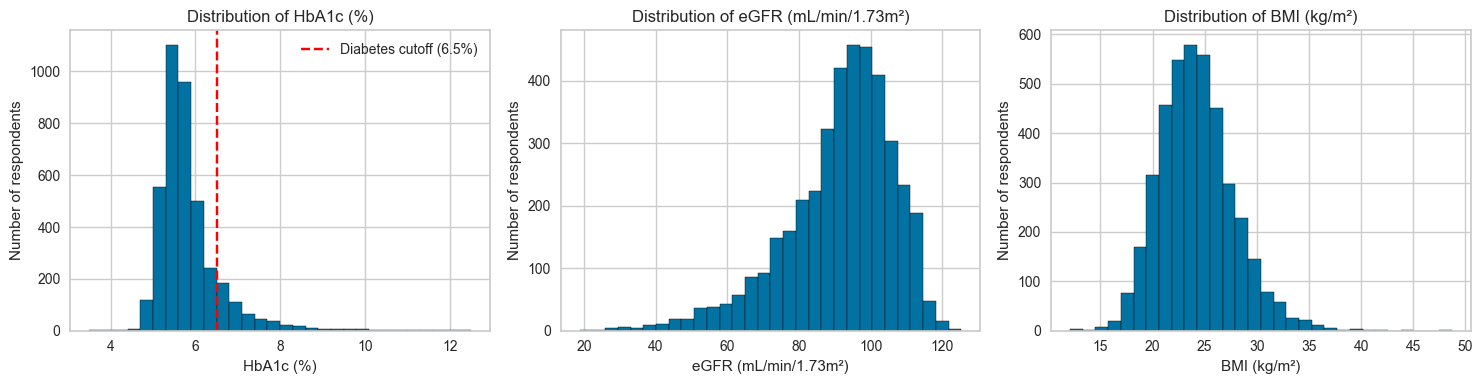

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cols   = ['HE_HbA1c', 'eGFR', 'HE_BMI']
labels = ['HbA1c (%)', 'eGFR (mL/min/1.73m²)', 'BMI (kg/m²)']

for ax, col, label in zip(axes, cols, labels):
    ax.hist(df_subset[col].dropna(), bins=30, edgecolor='black')
    ax.set_xlabel(label)
    ax.set_ylabel('Number of respondents')
    ax.set_title(f'Distribution of {label}')

# mark the diabetes threshold on the HbA1c plot (your diabetes = HbA1c ≥ 6.5%)
axes[0].axvline(6.5, color='red', linestyle='--', label='Diabetes cutoff (6.5%)')
axes[0].legend()

plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 4.5 EDA — Tooth-Loss Rate by Subgroup </h3>

<h4 style="color:#7FDBFF";> How tooth loss was derived: </h4>
Because O_TC is binary (0 or 1), taking the average of it gives you the fraction that are 1. For example, among 5 people 3 people have diabetes. That would result to 
O_TC values: [1, 0, 1, 1, 0]
sum of 1 = 3 
count = 5
therefore, mean = 3/5 = 60% ; the mean is the rate so 60% have tooth  

This concept relates to each histogram of education, income quartile, and diabetes 

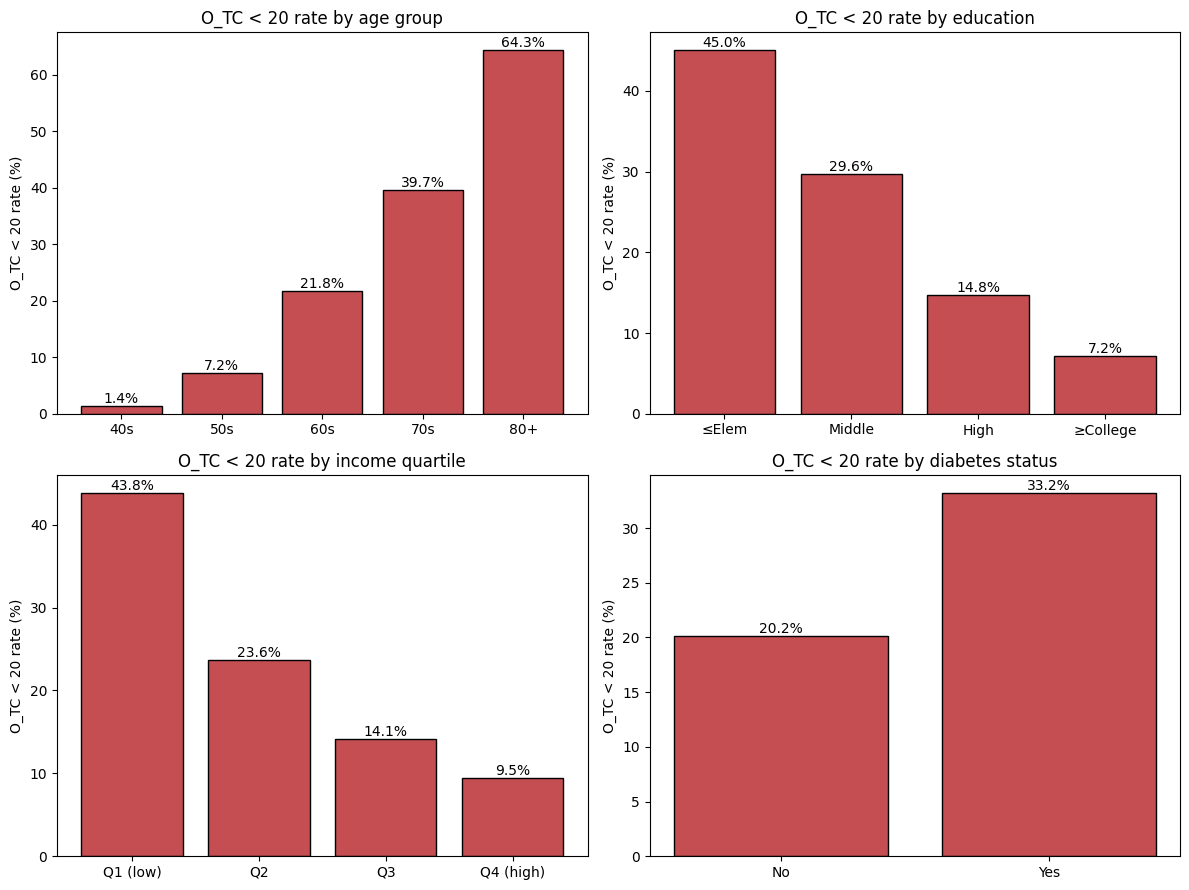

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

def plot_rate(ax, grouper, title, xlabels):
    rate = df_subset['O_TC_'].groupby(grouper, observed=True).mean() * 100   # mean of 0/1 = % in class 1
    bars = ax.bar(range(len(rate)), rate.values, color='#C44E52', edgecolor='black')
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels(xlabels)
    ax.set_ylabel('O_TC < 20 rate (%)')
    ax.set_title(title)
    for bar, v in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f'{v:.1f}%', ha='center', va='bottom')

# 1. Age group (80 is top-coded as 80+)
age_band = pd.cut(df_subset['age'], bins=[40, 50, 60, 70, 80, 200],
                  right=False, labels=['40s', '50s', '60s', '70s', '80+'])
plot_rate(axes[0, 0], age_band, 'O_TC < 20 rate by age group',
          ['40s', '50s', '60s', '70s', '80+'])

# 2. Education (1=≤elem ... 4=≥college)
plot_rate(axes[0, 1], df_subset['edu'], 'O_TC < 20 rate by education',
          ['≤Elem', 'Middle', 'High', '≥College'])

# 3. Income quartile (1=low ... 4=high)
plot_rate(axes[1, 0], df_subset['ho_incm'], 'O_TC < 20 rate by income quartile',
          ['Q1 (low)', 'Q2', 'Q3', 'Q4 (high)'])

# 4. Diabetes (HbA1c ≥ 6.5%)
diabetes = (df_subset['HE_HbA1c'] >= 6.5).map({False: 'No', True: 'Yes'})
plot_rate(axes[1, 1], diabetes, 'O_TC < 20 rate by diabetes status', ['No', 'Yes'])

plt.tight_layout()
plt.show()

<h2 style="color:#FFA500";> 5. Train / Test Split & Median Imputation </h2>

Split the cleaned dataset (80 / 20, stratified on `O_TC_`) then apply **median imputation** on the training fold. The fitted imputer is applied to the test set without refitting, preventing data leakage.


In [14]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

# Bin age into ordinal groups to reduce dominance in feature importance
# include_lowest=True makes first bin [40, 50] so age==40 is not excluded
df_subset['age_group'] = pd.cut(
    df_subset['age'],
    bins=[40, 50, 60, 70, 150],
    labels=[0, 1, 2, 3],
    include_lowest=True
).cat.codes.astype(float)  # cat.codes gives int, float needed for SimpleImputer

feature_cols = ['age_group', 'ho_incm', 'edu', 'BD1',
                'BM7', 'HE_HbA1c', 'HE_BMI', 'eGFR']

X = df_subset[feature_cols].replace([np.inf, -np.inf], np.nan)
# ^ It replaces positive/negative infinity values with NaN to prevent 
# downstream mathematical operations or matrix calculations from breaking.
y = df_subset['O_TC_']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# IMPUTING 

print(f"Total values imputed: {X_train.isna().sum().sum()}")
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test  = pd.DataFrame(imputer.transform(X_test),  columns=X_test.columns)

Total values imputed: 666


<h2 style="color:#FFA500";> 7. Class Imbalance — SMOTE (ratio 1 : 1.5) </h2>

The minority class (`O_TC_ = 1`, tooth count < 20) is underrepresented by a factor of ~3.6×. SMOTE is applied **inside each CV fold via an `ImbPipeline`** to prevent leakage — synthetic samples from the training fold never contaminate the validation fold.


In [15]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("Class distribution before SMOTE:")
print("Before:", pd.Series(y_train).value_counts().to_dict())
print("(SMOTE will now be applied inside each CV fold via pipeline — no standalone resampling)")


Class distribution before SMOTE:
Before: {0: 2593, 1: 724}
(SMOTE will now be applied inside each CV fold via pipeline — no standalone resampling)


<h2 style="color:#FFA500";> 8. Hyperparameter Tuning — RandomizedSearchCV </h2>
<h3 style="color:red;"> Use optuma library </h3> 
**Method:** `RandomizedSearchCV` with 5-fold `StratifiedKFold`, 50 iterations per model, scored by `roc_auc`. SMOTE is embedded inside each fold pipeline to avoid leakage.

| Model | Key hyperparameters tuned |
|-------|--------------------------|
| **Random Forest** | `n_estimators`, `max_depth`, `min_samples_leaf` |
| **XGBoost** | `n_estimators`, `max_depth`, `learning_rate`, `subsample` |
| **LightGBM** | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples` |
| **Logistic Regression** | `C`, `penalty` (L1 / L2 via SAGA solver) |



**Method:** RandomizedSearchCV (faster than GridSearch for 5 models; 50 iterations per model, `scoring = 'roc_auc'`)

| Model                   | Key Hyperparameters                                                | Tuning Range                                     |
| :---------------------- | :----------------------------------------------------------------- | :----------------------------------------------- |
| **Random Forest**       | `n_estimators`, `max_depth`, `min_samples_leaf`                    | 100/300/500 · 5/10/15/None · 1/5/10              |
| **XGBoost**             | `n_estimators`, `max_depth`, `learning_rate`, `subsample`          | 100/300/500 · 3/5/7 · 0.01/0.1/0.3 · 0.7/0.8/1.0 |
| **LightGBM**            | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples` | 100/300/500 · 15/31/63 · 0.01/0.1/0.3 · 5/10/20  |
| **Logistic Regression** | `C`, `penalty`                                                     | 0.01/0.1/1/10 · L1/L2                            |


<h3 style="color:yellow";> 8.1 Fit & Search -- based on my models </h3>

#### include catboost 


In [16]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression

param_grids = {
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42), # <-- criterion is 'gini' default is gini impurity
        'params': {
            'model__n_estimators':     [100, 300, 500],
            'model__max_depth':        [5, 10, 15, None],
            'model__min_samples_leaf': [1, 5, 10]
        }
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, eval_metric='logloss'), # <-- not loss function but evaluation metric
        # ^ since O_TC_ is binary --> it takes binary:logistic or logistic loss (binary cross-entropy/log loss)
        'params': {
            'model__n_estimators':  [100, 300, 500],
            'model__max_depth':     [3, 5, 7],
            'model__learning_rate': [0.01, 0.1, 0.3],
            'model__subsample':     [0.7, 0.8, 1.0]
        }
    },
    # extremely fast; instead of level wise growth its leaf wise growth (vertical); high speed but prone to OVERFITTING
    'LightGBM': {
        'model': LGBMClassifier(random_state=42, verbose=-1), # <-- uses binary cross entropy as loss function too
        'params': {
            'model__n_estimators':      [100, 300, 500],
            'model__num_leaves':        [15, 31, 63],
            'model__learning_rate':     [0.01, 0.1, 0.3],
            'model__min_child_samples': [5, 10, 20] # <-- main overfitting guard (forces each leaf to )
            #hold enough samples so it can'tmemorize a handful of points) 
        }
    },
    # LR is scale-sensitive (L1/L2 penalty + saga solver), so the scaler is refit
    # inside each CV fold via a nested pipeline. Tree models above stay unscaled (scale-invariant).
    'Logistic Regression': {
        'model': ImbPipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(random_state=42, max_iter=1000, solver='saga'))
        ]),
        'params': {
            'model__model__C':       [0.01, 0.1, 1, 10],   # nested: outer 'model' step -> inner 'model' step
            'model__model__penalty': ['l1', 'l2']
        }
    },
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, config in param_grids.items():
    # SMOTE is inside the pipeline so it only sees training folds during CV (no leakage) -- this was because 
    # the AUC scores for all models were a bit too high (over 0.95) this assumes a leakage 
    # what does data leakage mean -> info from validation set "leaks" to the training process --> basically cheating
    # 
    pipeline = ImbPipeline([
        ('smote', SMOTE(sampling_strategy=1/1.5, random_state=42)),
        ('model', config['model'])
    ])
    #from here on is the testing of models 
    search = RandomizedSearchCV(
        estimator           = pipeline,
        param_distributions = config['params'],
        n_iter              = 50,
        cv                  = cv,
        scoring             = 'roc_auc',
        random_state        = 42,
        n_jobs              = -1
    )
    search.fit(X_train, y_train)  # original X_train — SMOTE applied inside each fold
    results[name] = {
        'best_params':   search.best_params_,
        'best_cv_score': search.best_score_
    }
    print(f"{name}: Best AUC = {search.best_score_:.4f} | Params: {search.best_params_}")

results_df = pd.DataFrame(
    {name: {'AUC': v['best_cv_score']} for name, v in results.items()}
).T.sort_values('AUC', ascending=False)
print(results_df)


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 36 is smaller than n_iter=50. Running 36 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Random Forest: Best AUC = 0.8212 | Params: {'model__n_estimators': 100, 'model__min_samples_leaf': 10, 'model__max_depth': 5}
XGBoost: Best AUC = 0.8269 | Params: {'model__subsample': 1.0, 'model__n_estimators': 500, 'model__max_depth': 3, 'model__learning_rate': 0.01}
LightGBM: Best AUC = 0.8250 | Params: {'model__num_leaves': 15, 'model__n_estimators': 300, 'model__min_child_samples': 10, 'model__learning_rate': 0.01}
Logistic Regression: Best AUC = 0.8222 | Params: {'model__model__penalty': 'l1', 'model__model__C': 0.01}


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 8 is smaller than n_iter=50. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


                          AUC
XGBoost              0.826946
LightGBM             0.824951
Logistic Regression  0.822247
Random Forest        0.821244


<h2 style="color:#FFA500";> 9. PyCaret Screening — Top 3 Models by AUC </h2>

Use PyCaret's `compare_models` as an automated second opinion across a broader algorithm pool. Fix class imbalance and normalise inside the setup so results are directly comparable to the manual tuning above. The top 3 models by cross-validated AUC are retained for visualisation.


#### feature extraction included

In [17]:
from pycaret.classification import *

feature_cols = ['age_group', 'ho_incm', 'edu', 'BD1',
                'BM7', 'HE_HbA1c', 'HE_BMI', 'eGFR', 'O_TC_']

df_train = df_subset[feature_cols].copy()

clf = setup(
    data          = df_train,
    target        = 'O_TC_',
    fix_imbalance = True,
    normalize     = True,
    fold          = 5,
    fold_strategy = 'stratifiedkfold',
    session_id    = 42
)

best_models = compare_models(sort='AUC', n_select=3)

,Description,Value
0,Session id,42
1,Target,O_TC_
2,Target type,Binary
3,Original data shape,"(4147, 9)"
4,Transformed data shape,"(5783, 9)"
5,Transformed train set shape,"(4538, 9)"
6,Transformed test set shape,"(1245, 9)"
7,Numeric features,8
8,Rows with missing values,7.8%
9,Preprocess,True


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
ridge,Ridge Classifier,0.7185,0.8198,0.7883,0.4225,0.5500,0.3714,0.4098,0.0240
lda,Linear Discriminant Analysis,0.7185,0.8198,0.7883,0.4225,0.5500,0.3714,0.4098,0.0100
lr,Logistic Regression,0.7298,0.8191,0.7662,0.4333,0.5532,0.3805,0.4125,0.2940
gbc,Gradient Boosting Classifier,0.7963,0.8181,0.5261,0.5376,0.5300,0.4004,0.4015,0.1260
ada,Ada Boost Classifier,0.7819,0.8173,0.5766,0.5014,0.5358,0.3943,0.3963,0.0460
nb,Naive Bayes,0.7257,0.8066,0.7709,0.4291,0.5508,0.3759,0.4099,0.1620
rf,Random Forest Classifier,0.7888,0.8046,0.4187,0.5212,0.4626,0.3336,0.3375,0.0820
svm,SVM - Linear Kernel,0.7064,0.8043,0.8041,0.4120,0.5445,0.3598,0.4041,0.0180
lightgbm,Light Gradient Boosting Machine,0.7950,0.8042,0.4361,0.5394,0.4794,0.3543,0.3588,0.3000
qda,Quadratic Discriminant Analysis,0.7026,0.8008,0.7631,0.4043,0.5283,0.3401,0.3769,0.0100


<h2 style="color:#FFA500";> 10. Visualisation — Confusion Matrix, Feature Importance, ROC Curve </h2>

Generate and save diagnostic plots for each of the 3 best PyCaret models. The AUC plot is skipped for models that lack `predict_proba` (e.g. LinearSVC).


In [18]:
for m in best_models:
    print(type(m).__name__)

RidgeClassifier
LinearDiscriminantAnalysis
LogisticRegression


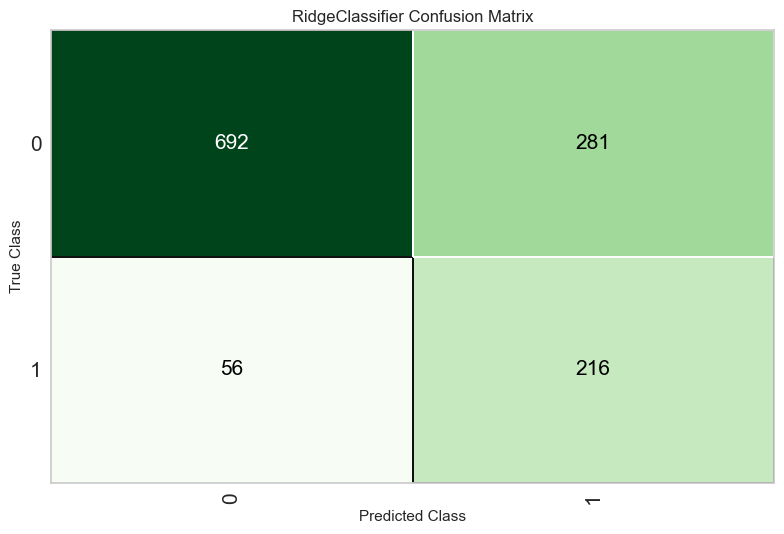

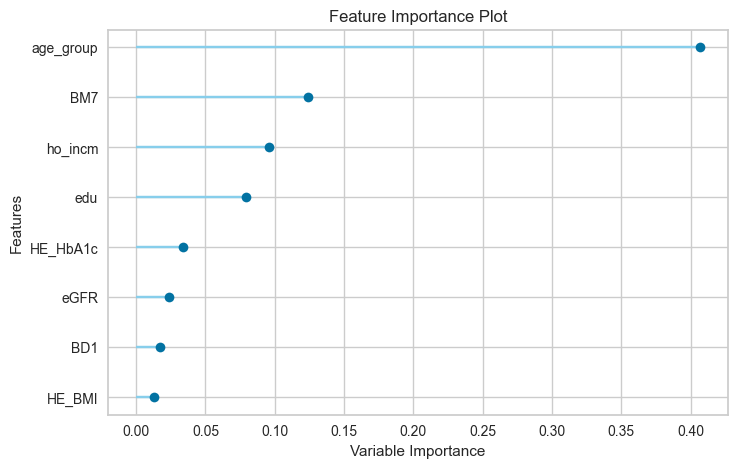

RidgeClassifier: AUC plot skipped (no predict_proba)


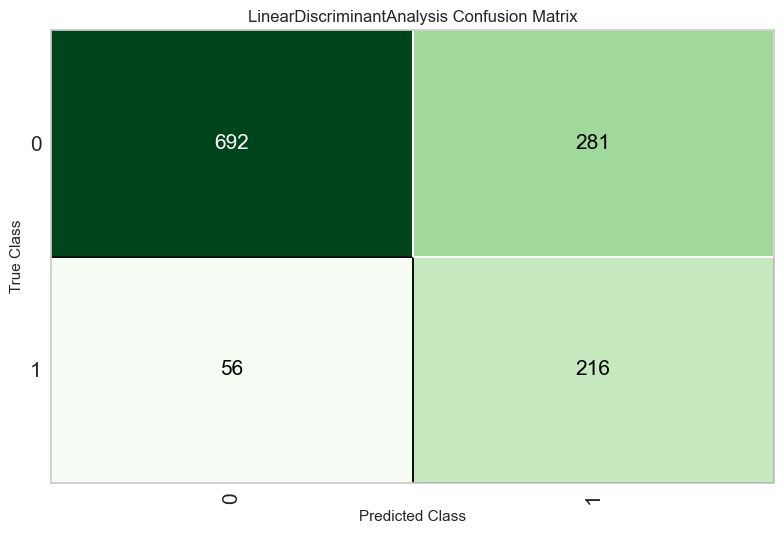

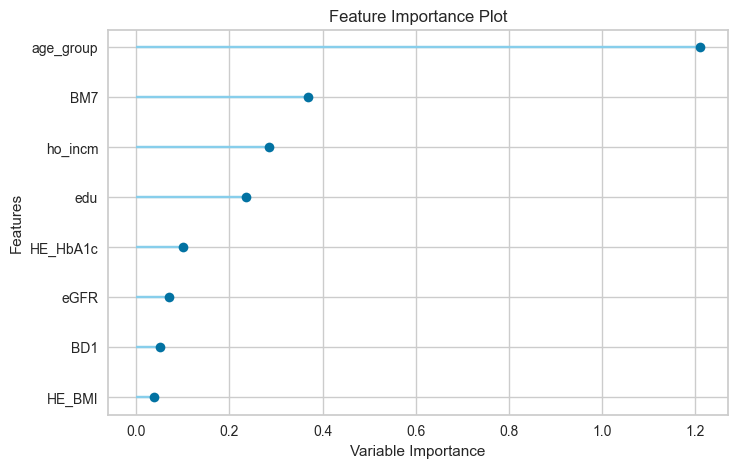

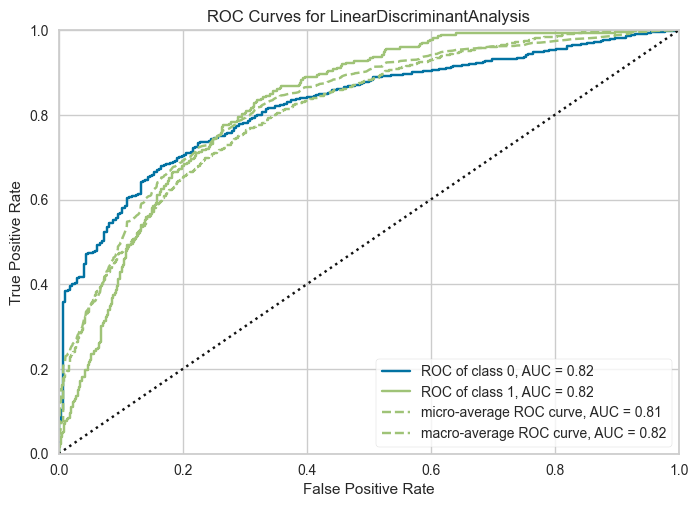

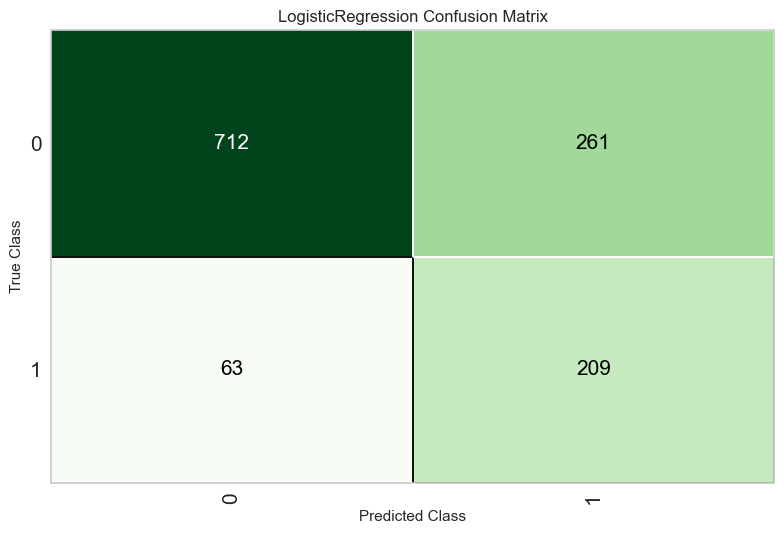

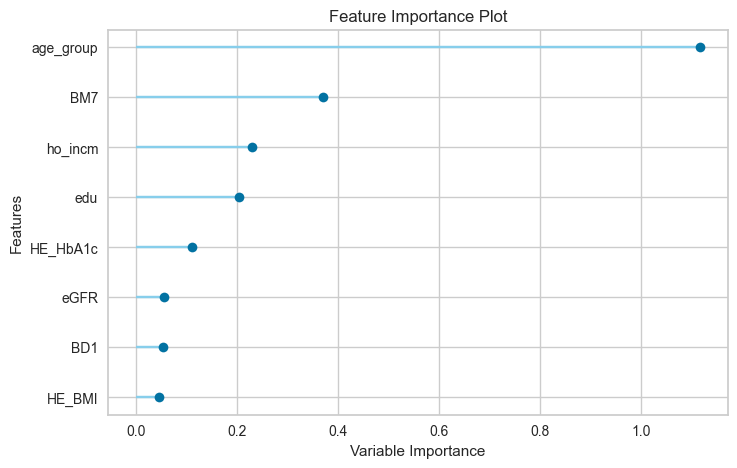

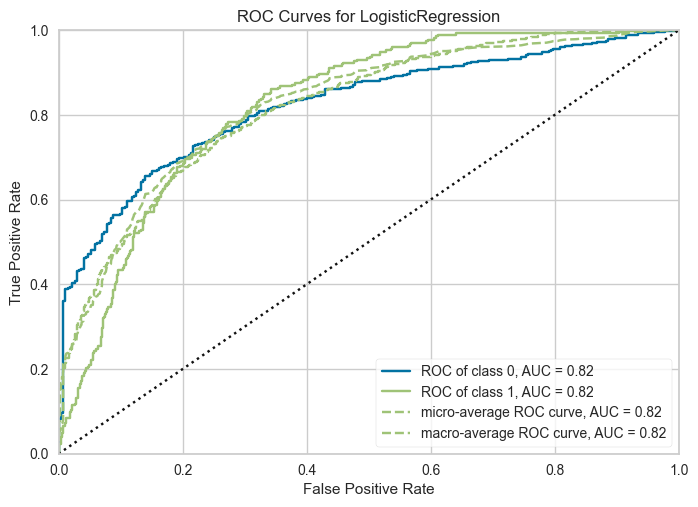

In [19]:

from pycaret.classification import *

for model in best_models:
    name = type(model).__name__
    plot_model(model, plot='confusion_matrix')
    plot_model(model, plot='feature')
    if hasattr(model, 'predict_proba'):
        plot_model(model, plot='auc')
    else:
        print(f"{name}: AUC plot skipped (no predict_proba)")


<h3 style="color:yellow";> 10.1 ROC Curve Comparison </h3>

Display all three ROC curves in sequence for side-by-side AUC comparison.

RidgeClassifier: AUC plot skipped (no predict_proba)


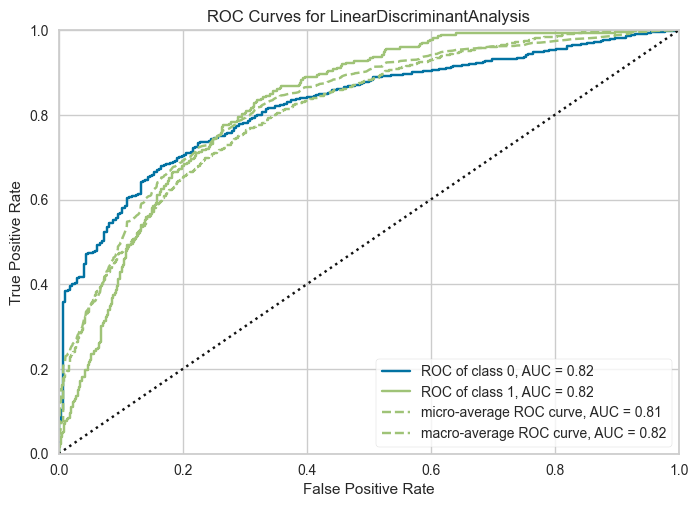

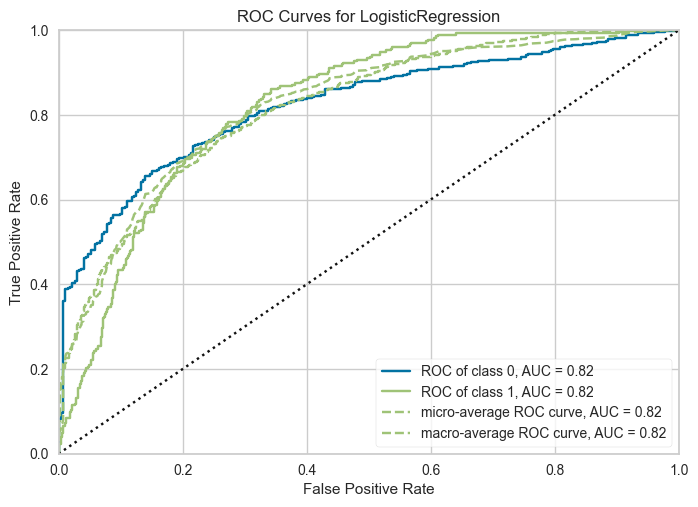

In [20]:
# All 3 ROC curves in sequence for comparison

for model in best_models:
    name = type(model).__name__
    if hasattr(model, 'predict_proba'):
        plot_model(model, plot='auc')
    else:
        print(f"{name}: AUC plot skipped (no predict_proba)")

<h2 style="color:#FFA500";> 11. Inferential Analysis — Multivariable Logistic Regression </h2>

The sections above answer *"what predicts tooth loss?"* (prediction). The research question is different — *"do CKD (eGFR), diabetes, and SES affect tooth loss **independently of age and other confounders**?"* That is an **explanatory** question, answered with logistic regression reporting **adjusted odds ratios (aOR)**, not feature importance.

- **Outcome:** `O_TC_` (1 = tooth loss, < 20 teeth)
- **Exposures of interest:** eGFR (CKD), diabetes (HbA1c ≥ 6.5%), income (`ho_incm`), education (`edu`)
- **Adjustment covariates:** age, sex, alcohol (`BD1`)
- **No SMOTE** — resampling distorts class proportions and biases odds ratios; it is valid only for the predictive models above.
- **Complete-case** analysis (rows with any missing model variable are dropped).

<h4 style="color:#7FDBFF";> McFadden pseudo-R² </h4>
How to Interpret It
- Scale: it ranges from 0 to just under 1. Higher values generally indicate that a model has better predictive power.
- McFadden's Rule of Thumb: Values between \(0.2\) and \(0.4\) indicate an "excellent" model fit.
- Difference from Standard R²: Unlike linear regression, this metric does not represent the percentage of variance explained in the dependent variable

In [21]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Build modelling frame from the cleaned df_subset.
# sex was dropped after the eGFR step, so recover it by index from the original df.
reg = df_subset.copy()
reg['sex_female'] = (df.loc[reg.index, 'sex'] == 2).astype(float)
reg['diabetes']   = (reg['HE_HbA1c'] >= 6.5).astype(float)
reg.loc[reg['HE_HbA1c'].isna(), 'diabetes'] = np.nan   # keep missing as missing

exposures  = ['eGFR', 'diabetes', 'ho_incm', 'edu']
covariates = ['age', 'sex_female', 'BD1']
model_vars = exposures + covariates

# complete-case; NO SMOTE (would bias the odds ratios)
m = reg[['O_TC_'] + model_vars].replace([np.inf, -np.inf], np.nan).dropna()
print(f"Complete-case n = {len(m)}  |  tooth-loss prevalence = {m['O_TC_'].mean():.1%}")

y = m['O_TC_']
X = sm.add_constant(m[model_vars])
res = sm.Logit(y, X).fit(disp=0)

OR = np.exp(res.params)
ci = np.exp(res.conf_int()); ci.columns = ['CI 2.5%', 'CI 97.5%']
or_table = pd.DataFrame({
    'aOR':      OR,
    'CI 2.5%':  ci['CI 2.5%'],
    'CI 97.5%': ci['CI 97.5%'],
    'p-value':  res.pvalues
}).loc[['const'] + model_vars]

print("\n=== Adjusted odds ratios ===")
print(or_table.round(4).to_string())
print(f"\nMcFadden pseudo-R² = {res.prsquared:.3f}")

Complete-case n = 3882  |  tooth-loss prevalence = 20.3%

=== Adjusted odds ratios ===
               aOR  CI 2.5%  CI 97.5%  p-value
const       0.0022   0.0005    0.0099   0.0000
eGFR        0.9986   0.9918    1.0055   0.6880
diabetes    1.4801   1.1753    1.8639   0.0009
ho_incm     0.9109   0.8279    1.0021   0.0553
edu         0.7399   0.6711    0.8157   0.0000
age         1.0983   1.0838    1.1129   0.0000
sex_female  0.6027   0.4951    0.7336   0.0000
BD1         0.9640   0.7527    1.2345   0.7713

McFadden pseudo-R² = 0.228


<h3 style="color:yellow";> 11.1 Collinearity Check (VIF) </h3>

eGFR is derived using age, so we verify it is not collinear with the `age` covariate. VIF must be computed **with an intercept** — omitting it inflates VIF for variables whose mean is far from zero. Rule of thumb: VIF > 5 warrants attention, > 10 is serious.

In [22]:
Xc = sm.add_constant(m[model_vars].astype(float))
vif = pd.Series(
    [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])],
    index=Xc.columns
).drop('const')
print("VIF (with intercept):")
print(vif.sort_values(ascending=False).round(2).to_string())

VIF (with intercept):
age           2.35
edu           1.85
eGFR          1.58
ho_incm       1.38
BD1           1.14
sex_female    1.13
diabetes      1.03


<h3 style="color:yellow";> 11.2 Correlation Heatmap — Regression Features </h3>

The visual companion to the VIF table above. VIF gives the number; this shows the
full pairwise correlation picture among the complete-case regression features, so
you can see at a glance that no two predictors are strongly collinear.

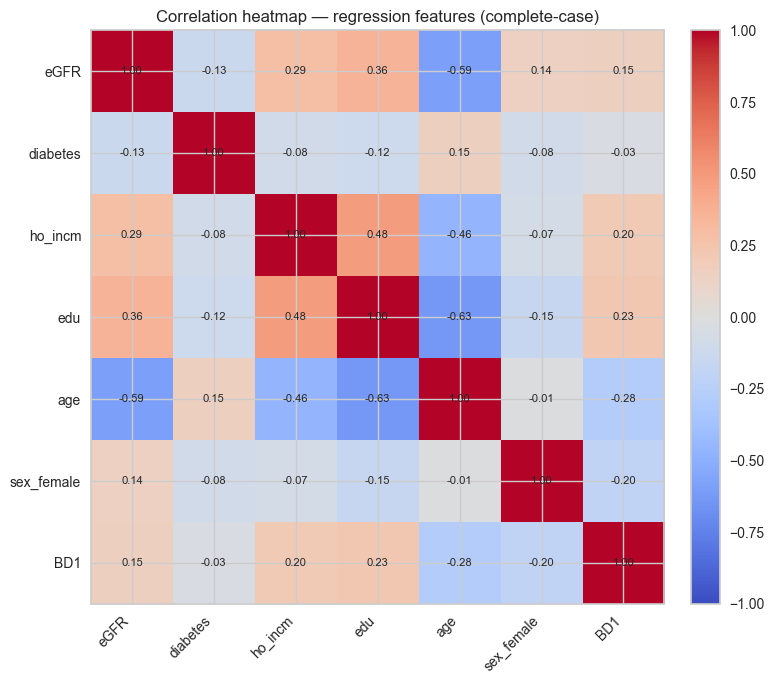

In [23]:
corr = m[model_vars].corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(model_vars)))
ax.set_yticks(range(len(model_vars)))
ax.set_xticklabels(model_vars, rotation=45, ha='right')
ax.set_yticklabels(model_vars)

# annotate each cell with its correlation value
for i in range(len(model_vars)):
    for j in range(len(model_vars)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title('Correlation heatmap — regression features (complete-case)')
plt.tight_layout()
plt.show()